# Geohash and the Guindy flyover → Chennai Central distance

This notebook:

1. explains what a **geohash** is and how it is built from a latitude and longitude, bit by bit,
2. implements **encode**, **decode** and **neighbours** by hand (no library) and tests them against published examples,
3. works out how big a geohash cell is for each length, and so how precise each length is,
4. geohashes the cleaned report locations from `Location_Normalisation.ipynb`,
5. runs the experiment: **the distance between the Guindy (Kathipara) flyover and Chennai Central**, comparing what a geohash tells you with the true distance,
6. explains how geohashes are used in Elasticsearch.

### Contents
1. What a geohash is
2. Encoding bit by bit (worked example)
3. Implementation and tests
4. Cell size and precision per length
5. Geohashing the cleaned report locations
6. Experiment: Guindy flyover → Chennai Central
7. Geohash in Elasticsearch
8. Summary

## 1. What a geohash is

A geohash turns a point into a **short string**, such as `tf346tw7p` for Chennai Central. Each extra character narrows down where the point is.

**The idea is repeated halving.**

* Longitude runs from −180° to +180°. Ask: is the point in the east half or the west half? Write `1` for east and `0` for west, then keep only that half.
* Do the same for latitude between −90° and +90°: `1` for north, `0` for south.
* **Alternate** the questions: longitude, latitude, longitude, latitude, … Each bit halves the box the point must lie in.
* Group the bits **5 at a time**. Each group of 5 bits is a number from 0 to 31, written as one character from this 32‑character alphabet:

```
0123456789bcdefghjkmnpqrstuvwxyz      (no a, i, l, o, so they can't be confused with 1 and 0)
```

So each character adds 5 bits, which makes the box 32 times smaller in area.

**Key property: a shared prefix means the same box.** Every point whose geohash starts with `tf3` lies inside one rectangle, about 150 km square, that covers Chennai. That makes geohashes useful for grouping, indexing and caching by area with plain text operations.

**Key limitation: the reverse isn't true.** Two points a metre apart can sit on opposite sides of a cell edge and share almost no prefix. Section 6.4 demonstrates this. A geohash is a coarse filter. Distance must still be calculated properly.

## 2. Encoding bit by bit (worked example)

Here is the trace for **Chennai Central (13.0825°N, 80.2750°E)**. At each step we take the current interval for the axis whose turn it is, compare the value with the midpoint, write the bit, and keep the half the point is in.

The rule for one step, with current interval $[lo, hi]$ and midpoint $mid = \tfrac{lo + hi}{2}$:

$$\text{bit} = \begin{cases}1 & \text{if } v \ge mid \;\Rightarrow\; lo \leftarrow mid\\ 0 & \text{if } v < mid \;\Rightarrow\; hi \leftarrow mid\end{cases}$$

Even‑numbered bits (0, 2, 4, …) are longitude and odd‑numbered bits are latitude.

In [1]:
import math, os, random
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

pd.set_option("display.precision", 6)
pd.set_option("display.max_colwidth", 70)

BASE32 = "0123456789bcdefghjkmnpqrstuvwxyz"
DECODE_MAP = {c: i for i, c in enumerate(BASE32)}

def encode_trace(lat, lon, n_bits):
    # Show every halving step used to build a geohash.
    lat_iv, lon_iv = [-90.0, 90.0], [-180.0, 180.0]
    rows = []
    for i in range(n_bits):
        axis = "lon" if i % 2 == 0 else "lat"
        iv, v = (lon_iv, lon) if axis == "lon" else (lat_iv, lat)
        mid = (iv[0] + iv[1]) / 2
        bit = 1 if v >= mid else 0
        rows.append({"bit #": i, "axis": axis, "interval": f"[{iv[0]:.5f}, {iv[1]:.5f}]",
                     "mid": mid, "value": v, "bit": bit})
        if bit:
            iv[0] = mid
        else:
            iv[1] = mid
    return pd.DataFrame(rows)

trace = encode_trace(13.0825, 80.2750, 15)
trace

,bit #,axis,interval,mid,value,bit
0,0,lon,"[-180.00000, 180.00000]",0.00000,80.2750,1
1,1,lat,"[-90.00000, 90.00000]",0.00000,13.0825,1
2,2,lon,"[0.00000, 180.00000]",90.00000,80.2750,0
3,3,lat,"[0.00000, 90.00000]",45.00000,13.0825,0
4,4,lon,"[0.00000, 90.00000]",45.00000,80.2750,1
5,5,lat,"[0.00000, 45.00000]",22.50000,13.0825,0
6,6,lon,"[45.00000, 90.00000]",67.50000,80.2750,1
7,7,lat,"[0.00000, 22.50000]",11.25000,13.0825,1
8,8,lon,"[67.50000, 90.00000]",78.75000,80.2750,1
9,9,lat,"[11.25000, 22.50000]",16.87500,13.0825,0


In [2]:
bits = "".join(str(b) for b in trace["bit"])
groups = [bits[i:i + 5] for i in range(0, len(bits), 5)]
for g in groups:
    print(f"{g}  ->  {int(g, 2):2d}  ->  '{BASE32[int(g, 2)]}'")
print("\nFirst 3 characters:", "".join(BASE32[int(g, 2)] for g in groups))

11001  ->  25  ->  't'
01110  ->  14  ->  'f'
00011  ->   3  ->  '3'

First 3 characters: tf3


Read the trace like this. Bit 0 asks whether 80.275° is at least 0°: yes, so `1`, and longitude is now [0, 180]. Bit 1 asks whether 13.08° is at least 0°: yes, so `1`, and latitude is now [0, 90]. And so on. Every group of 5 bits becomes one character.

## 3. Implementation and tests

* `encode(lat, lon, precision)` runs the halving loop above and emits a character every 5 bits.
* `decode_bbox(gh)` runs it backwards. Each character gives 5 bits, and each bit keeps one half of the current interval. The result is the cell's bounding box.
* `decode(gh)` returns the **centre** of that box and the **± error** in latitude and longitude. The true point can be anywhere in the box.
* `neighbours(gh)` finds the 8 surrounding cells of the same length by stepping one cell width or height from the centre and re‑encoding. Longitude wraps around at ±180°, and cells beyond the poles are skipped.

In [3]:
def encode(lat, lon, precision=9):
    if not (-90 <= lat <= 90 and -180 <= lon <= 180):
        raise ValueError(f"({lat}, {lon}) is not a valid latitude/longitude")
    lat_iv, lon_iv = [-90.0, 90.0], [-180.0, 180.0]
    chars, value, n_bits, even = [], 0, 0, True
    while len(chars) < precision:
        iv, v = (lon_iv, lon) if even else (lat_iv, lat)
        mid = (iv[0] + iv[1]) / 2
        if v >= mid:
            value = value * 2 + 1
            iv[0] = mid
        else:
            value = value * 2
            iv[1] = mid
        even = not even
        n_bits += 1
        if n_bits == 5:
            chars.append(BASE32[value])
            value, n_bits = 0, 0
    return "".join(chars)

def decode_bbox(gh):
    # Return (south, north, west, east) of the geohash cell.
    lat_iv, lon_iv = [-90.0, 90.0], [-180.0, 180.0]
    even = True
    for c in gh.lower():
        if c not in DECODE_MAP:
            raise ValueError(f"invalid geohash character {c!r}")
        v = DECODE_MAP[c]
        for shift in range(4, -1, -1):
            iv = lon_iv if even else lat_iv
            mid = (iv[0] + iv[1]) / 2
            if (v >> shift) & 1:
                iv[0] = mid
            else:
                iv[1] = mid
            even = not even
    return lat_iv[0], lat_iv[1], lon_iv[0], lon_iv[1]

def decode(gh):
    # Return (lat, lon, lat_error, lon_error): cell centre and half-size in degrees.
    s, n, w, e = decode_bbox(gh)
    return (s + n) / 2, (w + e) / 2, (n - s) / 2, (e - w) / 2

DIRECTIONS = {"n": (1, 0), "ne": (1, 1), "e": (0, 1), "se": (-1, 1),
              "s": (-1, 0), "sw": (-1, -1), "w": (0, -1), "nw": (1, -1)}

def neighbours(gh):
    s, n, w, e = decode_bbox(gh)
    lat, lon, dlat, dlon = (s + n) / 2, (w + e) / 2, n - s, e - w
    out = {}
    for name, (dy, dx) in DIRECTIONS.items():
        la = lat + dy * dlat
        if not -90 < la < 90:
            continue
        lo = (lon + dx * dlon + 180) % 360 - 180
        out[name] = encode(la, lo, len(gh))
    return out

**Tests**

1. **Published examples.** Wikipedia's geohash article uses `u4pruydqqvj` for (57.64911, 10.40744) and decodes `ezs42` to about (42.6, −5.6).
2. **Decoding contains the original point.** For 2,000 random points and every length from 1 to 12, the decoded box must contain the point.
3. **Prefixes nest.** Each cell lies inside the cell of its prefix.
4. **Neighbours touch.** Each neighbour shares an edge or corner with the cell.

In [4]:
assert encode(57.64911, 10.40744, 11) == "u4pruydqqvj"
lat, lon, lat_err, lon_err = decode("ezs42")
print(f"ezs42 -> ({lat:.4f} ± {lat_err:.4f}, {lon:.4f} ± {lon_err:.4f})")
assert abs(lat - 42.6) < 0.03 and abs(lon - (-5.6)) < 0.03

random.seed(42)
for _ in range(2000):
    la, lo = random.uniform(-90, 90), random.uniform(-180, 180)
    full = encode(la, lo, 12)
    for p in range(1, 13):
        gh = full[:p]
        assert encode(la, lo, p) == gh                       # prefixes nest
        s, n, w, e = decode_bbox(gh)
        assert s <= la <= n and w <= lo <= e                 # decoded box contains the point

gh = encode(13.0825, 80.2750, 6)
s, n, w, e = decode_bbox(gh)
for name, nb in neighbours(gh).items():
    s2, n2, w2, e2 = decode_bbox(nb)
    touches = (math.isclose(s2, n) or math.isclose(n2, s) or math.isclose(s2, s)) and \
              (math.isclose(w2, e) or math.isclose(e2, w) or math.isclose(w2, w))
    assert touches, name
print("All tests passed.")
print(f"Neighbours of {gh}:", neighbours(gh))

ezs42 -> (42.6050 ± 0.0220, -5.6030 ± 0.0220)


All tests passed.
Neighbours of tf346t: {'n': 'tf346w', 'ne': 'tf346y', 'e': 'tf346v', 'se': 'tf346u', 's': 'tf346s', 'sw': 'tf346k', 'w': 'tf346m', 'nw': 'tf346q'}


## 4. Cell size and precision per length

With precision $p$ there are $5p$ bits. Longitude gets the even‑numbered ones and latitude the odd‑numbered ones:

$$b_\lambda = \left\lceil \tfrac{5p}{2} \right\rceil,\qquad b_\varphi = \left\lfloor \tfrac{5p}{2} \right\rfloor$$

$$\text{cell height} = \frac{180^\circ}{2^{b_\varphi}},\qquad \text{cell width} = \frac{360^\circ}{2^{b_\lambda}}$$

Converting to kilometres: one degree of latitude is $\frac{\pi R}{180} \approx 111.19$ km. One degree of longitude is $111.19\cos\varphi$ km, so it shrinks towards the poles. **The same geohash length therefore gives narrower cells further north or south.** The table is for Chennai's latitude (about 13°N).

The largest possible error when you use the cell centre in place of the real point is **half the cell's diagonal**.

In [5]:
R_EARTH_KM = 6371.0088
KM_PER_DEG = math.pi * R_EARTH_KM / 180

def haversine_km(lat1, lon1, lat2, lon2):
    # Great-circle distance on a sphere (formula in section 6.2).
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    dphi, dlam = phi2 - phi1, math.radians(lon2 - lon1)
    a = math.sin(dphi / 2) ** 2 + math.cos(phi1) * math.cos(phi2) * math.sin(dlam / 2) ** 2
    return 2 * R_EARTH_KM * math.asin(math.sqrt(a))

def cell_size_km(precision, lat):
    n_bits = 5 * precision
    lon_bits, lat_bits = (n_bits + 1) // 2, n_bits // 2
    h_deg, w_deg = 180 / 2 ** lat_bits, 360 / 2 ** lon_bits
    h_km = h_deg * KM_PER_DEG
    w_km = w_deg * KM_PER_DEG * math.cos(math.radians(lat))
    return h_deg, w_deg, h_km, w_km

def fmt_len(km):
    return f"{km:,.1f} km" if km >= 1 else (f"{km * 1000:,.1f} m" if km >= 0.001 else f"{km * 1e5:.1f} cm")

rows = []
for p in range(1, 13):
    h_deg, w_deg, h_km, w_km = cell_size_km(p, 13.04)
    rows.append({"length": p, "bits (lon+lat)": f"{(5*p+1)//2}+{5*p//2}",
                 "cell width": fmt_len(w_km), "cell height": fmt_len(h_km),
                 "max error (½ diagonal)": fmt_len(math.hypot(w_km, h_km) / 2)})
pd.DataFrame(rows).set_index("length")

,bits (lon+lat),cell width,cell height,max error (½ diagonal)
length,,,,
1,3+2,"4,874.7 km","5,003.8 km","3,492.9 km"
2,5+5,"1,218.7 km",625.5 km,684.9 km
3,8+7,152.3 km,156.4 km,109.2 km
4,10+10,38.1 km,19.5 km,21.4 km
5,13+12,4.8 km,4.9 km,3.4 km
6,15+15,1.2 km,610.8 m,668.9 m
7,18+17,148.8 m,152.7 m,106.6 m
8,20+20,37.2 m,19.1 m,20.9 m
9,23+22,4.6 m,4.8 m,3.3 m


A rough guide: **5 characters ≈ town district, 7 ≈ street, 9 ≈ building/doorway**.

## 5. Geohashing the cleaned report locations

These are the cleaned WGS84 points from `Location_Normalisation.ipynb`, read from `locations_clean.csv`. Records without a valid location (L5, L6) get no geohash.

In [6]:
clean = pd.read_csv("locations_clean.csv")
valid = clean[clean["lat"].notna()].copy()
valid["geohash_5"] = [encode(a, b, 5) for a, b in zip(valid["lat"], valid["lon"])]
valid["geohash_9"] = [encode(a, b, 9) for a, b in zip(valid["lat"], valid["lon"])]
valid[["id", "place", "lat", "lon", "status", "geohash_5", "geohash_9", "km_from_cp"]]

,id,place,lat,lon,status,geohash_5,geohash_9,km_from_cp
0,L1,"Connaught Place, New Delhi",28.6139,77.20900,ok,ttnfu,ttnfucjbh,0.00
1,L2,Noida Sector 18,28.5700,77.32100,ok,ttnfx,ttnfx3p2m,11.98
2,L3,Jaipur,26.9125,75.78722,ok,tsvch,tsvche68d,235.29
3,L4,"Karol Bagh, New Delhi",28.6519,77.19090,corrected,ttnfu,ttnfuxbtq,4.58
6,L7,Meerut,28.9845,77.70640,ok,ttpkb,ttpkbk2nf,63.62
7,L8,Agra,27.1767,78.00810,corrected,tsz6x,tsz6x57gb,178.06
8,L9,Sonipat,28.9931,77.01510,ok,ttnub,ttnubw09j,46.20


In [7]:
def common_prefix(a, b):
    return os.path.commonprefix([a, b])

pts = list(valid.itertuples())
for i, a in enumerate(pts):
    for b in pts[i + 1:]:
        cp = common_prefix(a.geohash_9, b.geohash_9)
        if cp:
            km = haversine_km(a.lat, a.lon, b.lat, b.lon)
            print(f"{a.id} {a.place:<27} – {b.id} {b.place:<27} shared '{cp}' ({len(cp)} chars), {km:6.1f} km apart")

L1 Connaught Place, New Delhi  – L2 Noida Sector 18             shared 'ttnf' (4 chars),   12.0 km apart
L1 Connaught Place, New Delhi  – L3 Jaipur                      shared 't' (1 chars),  235.3 km apart
L1 Connaught Place, New Delhi  – L4 Karol Bagh, New Delhi       shared 'ttnfu' (5 chars),    4.6 km apart
L1 Connaught Place, New Delhi  – L7 Meerut                      shared 'tt' (2 chars),   63.6 km apart
L1 Connaught Place, New Delhi  – L8 Agra                        shared 't' (1 chars),  178.1 km apart
L1 Connaught Place, New Delhi  – L9 Sonipat                     shared 'ttn' (3 chars),   46.2 km apart
L2 Noida Sector 18             – L3 Jaipur                      shared 't' (1 chars),  238.2 km apart
L2 Noida Sector 18             – L4 Karol Bagh, New Delhi       shared 'ttnf' (4 chars),   15.6 km apart
L2 Noida Sector 18             – L7 Meerut                      shared 'tt' (2 chars),   59.5 km apart
L2 Noida Sector 18             – L8 Agra                        shar

Nearby points share longer prefixes. Connaught Place and Karol Bagh (4.6 km apart) share `ttnfu`. All three Delhi reports share `ttnf`. Sonipat (46 km) shares only `ttn`, and Jaipur and Agra only `t`. A prefix such as `ttnf` therefore groups the Delhi reports. Section 6.4 shows why a prefix can only group points and can't measure distance.

## 6. Experiment: Guindy flyover → Chennai Central

### 6.1 The two points

| Point | Latitude | Longitude | Source |
|---|---|---|---|
| **Guindy flyover** (Kathipara Junction cloverleaf, commonly called the Guindy flyover) | 13.00727°N | 80.20371°E | Wikipedia "Kathipara Junction" (13°00′26″N 80°12′13″E); AARoads gives the same decimal values |
| **Chennai Central** (Puratchi Thalaivar Dr. M.G. Ramachandran Central railway station) | 13.0825°N | 80.2750°E | Wikipedia "Chennai Central railway station" (13°04′57″N 80°16′30″E) |

"Guindy flyover" can also mean the flyover by **Guindy metro station** (13.009262°N, 80.213189°E). Section 6.6 shows how much that choice changes the answer.

In [8]:
GUINDY  = {"name": "Guindy (Kathipara) flyover", "lat": 13.00727, "lon": 80.20371}
CENTRAL = {"name": "Chennai Central",            "lat": 13.0825,  "lon": 80.2750}

for p in (GUINDY, CENTRAL):
    p["geohash"] = encode(p["lat"], p["lon"], 9)
    print(f"{p['name']:<28} ({p['lat']}, {p['lon']})  ->  {p['geohash']}")

shared = common_prefix(GUINDY["geohash"], CENTRAL["geohash"])
print(f"\nShared prefix: '{shared}' ({len(shared)} characters)")

Guindy (Kathipara) flyover   (13.00727, 80.20371)  ->  tf31cpfsc
Chennai Central              (13.0825, 80.275)  ->  tf346tw7p

Shared prefix: 'tf3' (3 characters)


### 6.2 The true distance

The same two methods as Part B of the first notebook:

**Haversine** (sphere, $R = 6371.0088$ km):

$$a = \sin^2\!\frac{\Delta\varphi}{2} + \cos\varphi_1\cos\varphi_2\sin^2\!\frac{\Delta\lambda}{2},\qquad d = 2R\arcsin\sqrt{a}$$

**Vincenty** (WGS84 ellipsoid, accurate to about a millimetre) as the check. We also compute the **initial bearing**, the compass direction you would start out in:

$$\theta = \operatorname{atan2}\big(\sin\Delta\lambda\cos\varphi_2,\; \cos\varphi_1\sin\varphi_2 - \sin\varphi_1\cos\varphi_2\cos\Delta\lambda\big)$$

In [9]:
WGS84 = {"a": 6378137.0, "inv_f": 298.257223563}

# haversine_km is defined in section 4

def vincenty_km(lat1, lon1, lat2, lon2, tol=1e-12, max_iter=200):
    a = WGS84["a"]; f = 1 / WGS84["inv_f"]; b = a * (1 - f)
    if (lat1, lon1) == (lat2, lon2):
        return 0.0
    L = math.radians(lon2 - lon1)
    U1 = math.atan((1 - f) * math.tan(math.radians(lat1)))
    U2 = math.atan((1 - f) * math.tan(math.radians(lat2)))
    sinU1, cosU1, sinU2, cosU2 = math.sin(U1), math.cos(U1), math.sin(U2), math.cos(U2)
    lam = L
    for _ in range(max_iter):
        sin_lam, cos_lam = math.sin(lam), math.cos(lam)
        sin_sigma = math.hypot(cosU2 * sin_lam, cosU1 * sinU2 - sinU1 * cosU2 * cos_lam)
        cos_sigma = sinU1 * sinU2 + cosU1 * cosU2 * cos_lam
        sigma = math.atan2(sin_sigma, cos_sigma)
        sin_alpha = cosU1 * cosU2 * sin_lam / sin_sigma
        cos2_alpha = 1 - sin_alpha ** 2
        cos_2sm = cos_sigma - 2 * sinU1 * sinU2 / cos2_alpha if cos2_alpha else 0.0
        C = f / 16 * cos2_alpha * (4 + f * (4 - 3 * cos2_alpha))
        lam_prev = lam
        lam = L + (1 - C) * f * sin_alpha * (
            sigma + C * sin_sigma * (cos_2sm + C * cos_sigma * (-1 + 2 * cos_2sm ** 2)))
        if abs(lam - lam_prev) < tol:
            break
    u2 = cos2_alpha * (a ** 2 - b ** 2) / b ** 2
    A = 1 + u2 / 16384 * (4096 + u2 * (-768 + u2 * (320 - 175 * u2)))
    B = u2 / 1024 * (256 + u2 * (-128 + u2 * (74 - 47 * u2)))
    d_sigma = B * sin_sigma * (cos_2sm + B / 4 * (cos_sigma * (-1 + 2 * cos_2sm ** 2)
              - B / 6 * cos_2sm * (-3 + 4 * sin_sigma ** 2) * (-3 + 4 * cos_2sm ** 2)))
    return b * A * (sigma - d_sigma) / 1000

def initial_bearing(lat1, lon1, lat2, lon2):
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    dlam = math.radians(lon2 - lon1)
    x = math.sin(dlam) * math.cos(phi2)
    y = math.cos(phi1) * math.sin(phi2) - math.sin(phi1) * math.cos(phi2) * math.cos(dlam)
    return (math.degrees(math.atan2(x, y)) + 360) % 360

A_, B_ = (GUINDY["lat"], GUINDY["lon"]), (CENTRAL["lat"], CENTRAL["lon"])
d_hav, d_vin = haversine_km(*A_, *B_), vincenty_km(*A_, *B_)
brg = initial_bearing(*A_, *B_)

dphi, dlam = B_[0] - A_[0], B_[1] - A_[1]
north_km = dphi * KM_PER_DEG
east_km = dlam * KM_PER_DEG * math.cos(math.radians((A_[0] + B_[0]) / 2))
print(f"Δlat = {dphi:.5f}°  ->  {north_km:.3f} km north")
print(f"Δlon = {dlam:.5f}°  ->  {east_km:.3f} km east   (× cos {((A_[0] + B_[0]) / 2):.3f}°)")
print(f"Pythagoras check   : {math.hypot(north_km, east_km):.3f} km")
print(f"Haversine          : {d_hav:.3f} km")
print(f"Vincenty (WGS84)   : {d_vin:.3f} km   (difference {1000 * (d_hav - d_vin):+.1f} m)")
print(f"Initial bearing    : {brg:.1f}° (north-east)")

Δlat = 0.07523°  ->  8.365 km north
Δlon = 0.07129°  ->  7.723 km east   (× cos 13.045°)
Pythagoras check   : 11.385 km
Haversine          : 11.385 km
Vincenty (WGS84)   : 11.360 km   (difference +24.4 m)
Initial bearing    : 42.7° (north-east)


### 6.3 Distance from the geohashes alone

Suppose we only stored the geohash and not the coordinates. We could decode each hash to its cell centre and measure between the centres. How close would that get to the true distance as the hash gets longer?

In [10]:
rows = []
for p in range(1, 11):
    ga, gb = encode(*A_, p), encode(*B_, p)
    la, lo, *_ = decode(ga)
    lb, lob, *_ = decode(gb)
    d = haversine_km(la, lo, lb, lob)
    rows.append({"length": p, "Guindy": ga, "Central": gb, "same cell": ga == gb,
                 "distance between centres (km)": d, "error vs true (m)": 1000 * (d - d_hav)})
geo_exp = pd.DataFrame(rows).set_index("length")
geo_exp

,Guindy,Central,same cell,distance between centres (km),error vs true (m)
length,,,,,
1,t,t,True,0.000000,-11384.818041
2,tf,tf,True,0.000000,-11384.818041
3,tf3,tf3,True,0.000000,-11384.818041
4,tf31,tf34,False,19.546010,8161.192156
5,tf31c,tf346,False,10.870869,-513.949163
6,tf31cp,tf346t,False,11.140682,-244.135976
7,tf31cpf,tf346tw,False,11.418319,33.501043
8,tf31cpfs,tf346tw7,False,11.379092,-5.725588
9,tf31cpfsc,tf346tw7p,False,11.387461,2.643066


* **Up to 3 characters** (`tf3`, about 150 km cells) both points are in the *same cell*, so the geohash distance is 0 km. A geohash can't separate two points closer together than its cell size.
* **At 4 characters** they fall in different cells, but the cells are about 38 × 20 km, so the centre‑to‑centre distance is off by about 8 km.
* **At 5–6 characters** the error drops to a few hundred metres. **At 7** (about 150 m cells) it is about 34 m, and **at 9** (about 5 m cells) about 3 m.

So you can only measure distance from geohashes if they are long enough. Elasticsearch keeps the full coordinate in a `geo_point` field for exactly this reason (section 7).

### 6.4 Why a shared prefix is not a distance

The `tf3` cell that holds both Guindy and Central has its western edge at 80.15625°E, about 5 km west of the Guindy flyover. Take two points **0.2 m apart** on opposite sides of that edge, at the flyover's latitude:

In [11]:
s, n, w, e = decode_bbox(encode(*A_, 3))         # the 'tf3' cell
eps = 1e-6                                        # degrees, about 0.1 m
p1, p2 = (A_[0], w + eps), (A_[0], w - eps)
g1, g2 = encode(*p1, 9), encode(*p2, 9)
print(f"Point 1 {p1} -> {g1}")
print(f"Point 2 {p2} -> {g2}")
print(f"Distance apart : {1000 * haversine_km(*p1, *p2):.2f} m")
print(f"Shared prefix  : '{common_prefix(g1, g2)}' ({len(common_prefix(g1, g2))} chars)")
print(f"Guindy→Central share '{shared}' ({len(shared)} chars) yet are {d_hav:.1f} km apart.")

Point 1 (13.00727, 80.156251) -> tf31bpbhb
Point 2 (13.00727, 80.156249) -> tf2czzzuz
Distance apart : 0.22 m
Shared prefix  : 'tf' (2 chars)
Guindy→Central share 'tf3' (3 chars) yet are 11.4 km apart.


The two points 0.2 m apart share only **2** characters, while Guindy and Central, 11.4 km apart, share **3**. **A shared prefix guarantees the same box, but different prefixes don't mean the points are far apart.** That's why the next step is needed.

### 6.5 Proximity search using geohash (coarse filter, then exact check)

The standard recipe for "find everything within *r* km":

1. Choose the **longest geohash whose cells are at least *r* wide and tall** at this latitude.
2. Candidate cells = the query point's cell **plus its 8 neighbours**. Any point within *r* must lie in one of these 9 cells.
3. Keep only points whose geohash starts with one of the 9 candidates. This is a cheap string match.
4. Compute the **exact distance** for the survivors and keep those with $d \le r$.

We check whether Chennai Central is within 12 km and within 10 km of the Guindy flyover:

In [12]:
def choose_precision(radius_km, lat):
    best = 1
    for p in range(1, 13):
        _, _, h_km, w_km = cell_size_km(p, lat)
        if min(h_km, w_km) >= radius_km:
            best = p
    return best

def within(center, point, radius_km):
    p = choose_precision(radius_km, center[0])
    cell = encode(*center, p)
    candidates = {cell, *neighbours(cell).values()}
    target = encode(*point, p)
    is_candidate = target in candidates
    d = haversine_km(*center, *point)
    return {"radius_km": radius_km, "precision": p, "query cell": cell,
            "Central's cell": target, "passes geohash filter": is_candidate,
            "exact km": round(d, 3), "within radius": is_candidate and d <= radius_km}

pd.DataFrame([within(A_, B_, 12), within(A_, B_, 10)])

,radius_km,precision,query cell,Central's cell,passes geohash filter,exact km,within radius
0,12,4,tf31,tf34,True,11.385,True
1,10,4,tf31,tf34,True,11.385,False


With a **12 km** radius, Central passes the geohash filter and the exact check (about 11.4 km), so it's a match. With **10 km** it still passes the coarse geohash filter, because the 9 cells cover more than a 10 km circle, but the **exact distance rejects it**. This is why the exact check in step 4 is always needed.

### 6.6 How much the choice of points matters

The answer depends on which point is taken as "the Guindy flyover" and which as "Central". Here are the alternatives found in public sources:

In [13]:
alts_a = {"Kathipara Junction (Wikipedia)": (13.00727, 80.20371),
          "Guindy metro station flyover (Wikipedia)": (13.009262, 80.213189)}
alts_b = {"Chennai Central (Wikipedia)": (13.0825, 80.2750),
          "Chennai Central (latitude.to)": (13.0760, 80.2718)}
pd.DataFrame([{"from": a, "to": b, "haversine km": round(haversine_km(*pa, *pb), 3)}
              for a, pa in alts_a.items() for b, pb in alts_b.items()])

,from,to,haversine km
0,Kathipara Junction (Wikipedia),Chennai Central (Wikipedia),11.385
1,Kathipara Junction (Wikipedia),Chennai Central (latitude.to),10.621
2,Guindy metro station flyover (Wikipedia),Chennai Central (Wikipedia),10.543
3,Guindy metro station flyover (Wikipedia),Chennai Central (latitude.to),9.766


The choice of reference points moves the answer anywhere between about 9.8 and 11.4 km. That spread of about 1.6 km is far larger than the 24 m difference between haversine and Vincenty. **When you quote the result, state which points you used.**

Also note that this is the **straight‑line (great‑circle) distance**. The road distance, for example via Anna Salai (Mount Road), is longer and needs a road network to calculate.

### 6.7 Map

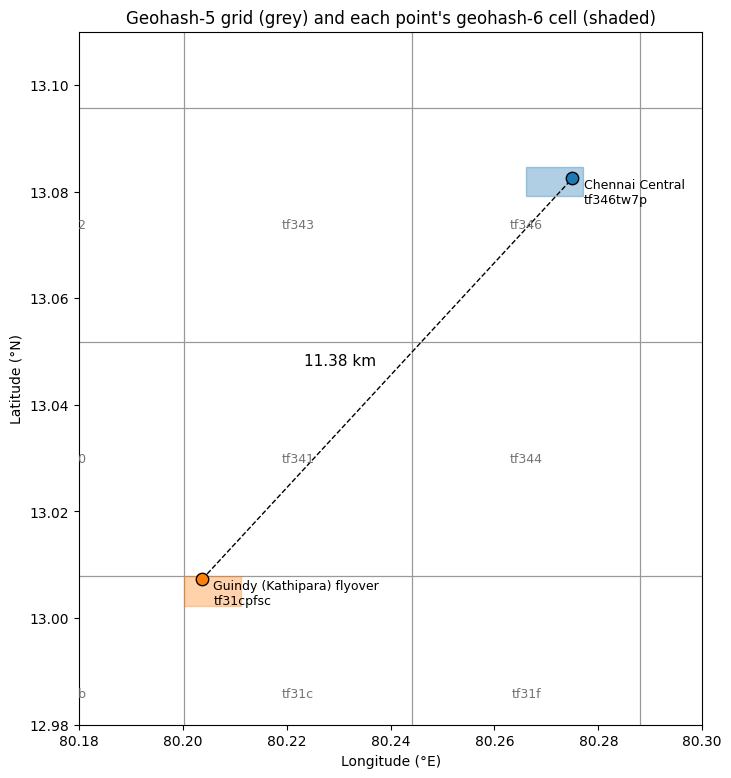

In [14]:
def cells_covering(south, north, west, east, precision):
    h_deg = 180 / 2 ** ((5 * precision) // 2)
    w_deg = 360 / 2 ** ((5 * precision + 1) // 2)
    out, lat = set(), south
    while lat <= north + h_deg:
        lon = west
        while lon <= east + w_deg:
            out.add(encode(min(lat, 89.999), lon, precision))
            lon += w_deg
        lat += h_deg
    return sorted(out)

fig, ax = plt.subplots(figsize=(9, 9))
for gh in cells_covering(12.98, 13.11, 80.18, 80.30, 5):
    s, n, w, e = decode_bbox(gh)
    ax.add_patch(mpatches.Rectangle((w, s), e - w, n - s, fill=False, lw=0.8, ec="0.6"))
    ax.text((w + e) / 2, (s + n) / 2, gh, ha="center", va="center", fontsize=9, color="0.45", clip_on=True)

for pt, colour in ((GUINDY, "tab:orange"), (CENTRAL, "tab:blue")):
    s, n, w, e = decode_bbox(encode(pt["lat"], pt["lon"], 6))
    ax.add_patch(mpatches.Rectangle((w, s), e - w, n - s, alpha=0.35, color=colour))
    ax.scatter(pt["lon"], pt["lat"], s=80, color=colour, edgecolor="k", zorder=3)
    ax.annotate(f"{pt['name']}\n{pt['geohash']}", (pt["lon"], pt["lat"]), xytext=(8, -18),
                textcoords="offset points", fontsize=9)

ax.plot([GUINDY["lon"], CENTRAL["lon"]], [GUINDY["lat"], CENTRAL["lat"]], "k--", lw=1)
mid = ((GUINDY["lon"] + CENTRAL["lon"]) / 2, (GUINDY["lat"] + CENTRAL["lat"]) / 2)
ax.annotate(f"{d_hav:.2f} km", mid, xytext=(-60, 10), textcoords="offset points", fontsize=11)

ax.set_xlim(80.18, 80.30); ax.set_ylim(12.98, 13.11)
ax.set_aspect(1 / math.cos(math.radians(13.04)))
ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°N)")
ax.set_title("Geohash-5 grid (grey) and each point's geohash-6 cell (shaded)")
plt.show()

## 7. Geohash in Elasticsearch

* **`geo_point` already accepts geohashes as input.** You can index `"location": "tf2f6..."` and Elasticsearch decodes it to the cell centre, so a short geohash input loses precision. It stores the point in a BKD tree, so `geo_distance` queries **don't need geohashes**. They use the exact coordinates.
* **Where geohashes help is grouping.** The `geohash_grid` aggregation groups points into geohash cells, for heat‑maps and "reports per area" counts:

```json
GET /locations_clean/_search
{
  "size": 0,
  "aggs": {
    "by_cell": { "geohash_grid": { "field": "location", "precision": 5 } }
  }
}
```

* **A stored geohash prefix** (for example a `keyword` field `geohash_5`) is useful for exact‑match grouping, cache keys or partitioning data by area. Any proximity search should still finish with an exact distance check, as in 6.5.
* As with the grid conversion, **compute geohashes when the data is loaded.** They are a pure function of the cleaned coordinates.

## 8. Summary

In [15]:
print("Guindy (Kathipara) flyover  13.00727 N, 80.20371 E   geohash", GUINDY["geohash"])
print("Chennai Central             13.0825  N, 80.2750  E   geohash", CENTRAL["geohash"])
print(f"Shared geohash prefix       '{shared}'  (same ~{cell_size_km(len(shared), 13.04)[3]:.0f} × "
      f"{cell_size_km(len(shared), 13.04)[2]:.0f} km cell)")
print(f"Straight-line distance      {d_hav:.2f} km (haversine)   {d_vin:.2f} km (Vincenty, WGS84)")
print(f"Direction                   {brg:.0f}° — Central is north-east of the flyover")
print(f"From 7-char geohashes only  {geo_exp.loc[7, 'distance between centres (km)']:.2f} km "
      f"(error {geo_exp.loc[7, 'error vs true (m)']:+.0f} m)")

Guindy (Kathipara) flyover  13.00727 N, 80.20371 E   geohash tf31cpfsc
Chennai Central             13.0825  N, 80.2750  E   geohash tf346tw7p
Shared geohash prefix       'tf3'  (same ~152 × 156 km cell)
Straight-line distance      11.38 km (haversine)   11.36 km (Vincenty, WGS84)
Direction                   43° — Central is north-east of the flyover
From 7-char geohashes only  11.42 km (error +34 m)


**What to tell the interviewer**

* Geohash encodes a point by repeatedly halving longitude and latitude in turn, then writes the bits 5 at a time in base‑32. Each character makes the cell 32 times smaller.
* It is very good for **grouping and coarse filtering** (shared prefix = same cell), but **not for measuring distance**. Nearby points can have different prefixes, and the decoded centre carries up to half a cell‑diagonal of error.
* For the Guindy flyover → Chennai Central question, the answer comes from the coordinates with haversine, checked with Vincenty. Geohash is used to show cell membership and as the coarse filter in a proximity search.